# Mock maker interface

This notebook provides the interface with the standard sirens mock generator used to produce the results presented in <a href="www.arxiv.org/abs/2007.14335">2007.14335</a>.

## Import packages

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys, platform, os
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import trapezoid

# speed of light
clight = 299792.458

## Set where the mock data file will be saved
If the `mock_data` directory does not exist locally, you need to create it before the mock can be saved.

In [2]:
outpath = 'mock_data/test_270126'

## Set the GW mock parameters
For more information on these parameters, see section A3 of 2007.14335 and references therein. In brief, we have:
* `binary_type`: the type of binaries in the observed mergers. Currently only `NS-NS` is available, i.e. two objects merging which each have a mass of $1.4 M_\odot$.
* `merger_model`: the merger rate model. Currently only the rate given below (`standard`) is available.
* `merger_distribution`: the distribution of the mergers as a function of redshift. Can be `weighted` or `uniform`.
* `sky_distribution`: the distribution of events across the sky. Currently only `uniform` is available.
* `inclination`: the inclination of orbital angular momentum to line of sight. Commonly set to zero (i.e. all events are seen face on).
* `t0`: the "fiducial epoch" of the merger. Also commonly set to zero.
* `psi_0`: the phase at that epoch. Set to zero.
* `f0`: a cut-off frequency (in Hz) which appears in the noise power spectral density of the detector (detector-dependent). See Table 1 (page 42) of 0903.0338.

### Current merger rate expression
\begin{equation}
    R(z) = \begin{cases} 1+2z &\text{if }z\leq1, \\ \frac{3}{4}(5-z) &\text{if }1<z<5, \\
    0 &\text{if } z\geq5.\end{cases}
\end{equation}
From 0906.3752.

### Current merger distribution
\begin{equation}
P(z) \propto \frac{4\pi r^2(z) R(z)}{H(z)(1+z)},
\end{equation}
where $r(z)$ is the comoving distance.

In [3]:
GWparameters = {'binary_type': 'NS-NS',         
                'merger_model': 'standard',     
                'merger_distribution': 'weighted',
                'sky_distribution': 'uniform',
                'inclination': 0.0,             
                't0': 0.,                      
                'psi_0': 0.,                    
                'f0': 200} # NH todo: move this to telescope specs                      

## Set the  detector specifications
Here we can set:
* `survey`: the detector we are creating mock data for. Currently only ET available; some of the internal settings of the mock maker like cut-off frequencies may need to be changed if another detector is introduced.
* `GW_number`: the number of observed events (i.e. the size of our mock dataset).
* `z_min`, `z_max`: the minimum and maximum redshifts.

In [4]:
specifications = {'survey': 'Einstein Telescope', 
                  'GW_number': 1000, 
                  'z_min': 0.001, 
                  'z_max': 5} 

## Set fiducial cosmology
Here we fix $\Omega_m$ and $H_0$, as well as the settings for the deviation from DDR due to photon-axion mixing and due to MG effects. 

The available options for the `EM_deviation` are `coherent` or `incoherent` magnetic fields (should have no effect on results); the decay amplitude `A` ($A=1$ is $\Lambda$CDM i.e. no DDR breaking); and `xi0`, effectively the transition probability (we can argue it's order 1). 

The options for the `GW_deviation` are the values of `Ga` and `Gn` (see eqn 4.16 in 2007.14335 for the definition). No deviation due to MG is recovered when $g_a=0$.

The intrinsic SNIa magnitude, $M_0$, is also set here. 

In [5]:
params = {'Omegam': 0.314,
          'H0': 67.36}

EM_deviation ={'model': 'incoherent', 
               'A': 1.,
               'xi0': 1.}


GW_deviation = {'Ga': 0.,
                'Gn': 2.}

M0 = -19.5 

zspecs = np.linspace(specifications['z_min'], specifications['z_max'], 1000)

## Compute relevant cosmological quantities
Here we compute the various distances etc.

In [6]:
z = np.linspace(0,specifications['z_max'], 1000)

Ez         = np.sqrt(params['Omegam']*(1 + z)**3 + (1 - params['Omegam']))
hubble     = interp1d(z, params['H0']*Ez, kind='cubic')

com = []
for zi in zspecs:
    zint  = np.linspace(0, zi, 100)
    dz    = (zi - 0.)/100
    com.append(clight*trapezoid(1/hubble(zint),zint,dx=dz))

comoving        = interp1d(zspecs, com, kind='cubic')
angular         = interp1d(zspecs, com/(1+zspecs), kind='cubic')
hubble_mpc      = interp1d(z, hubble(z)/clight, kind='cubic')

luminosity_LCDM = interp1d(zspecs, (1+zspecs)*com, kind='cubic')


from tools.theory import *

TH = theory(zspecs, comoving, angular, hubble, params['Omegam'], params['H0'], EM_deviation['A'],
            EM_deviation['xi0'], GW_deviation['Ga'], GW_deviation['Gn'], M0, EM_deviation['model'])

luminosity_GW = TH.GWobs()
luminosity_EM = TH.EMlumdist()

## Run the mock maker

In [7]:
from tools.merger_mock_maker import *

GW = compute_GWmock(params, GWparameters, specifications, outpath, hubble_mpc, comoving, luminosity_GW)

Welcome to the GW standard sirens mock maker!

output files will be produced in mock_data/test_270126_GWdataset.txt

Mock done and saved


In [8]:
from tools.snbao_mock import *

EM = compute_SNBAOmock(params,zspecs,outpath,hubble,angular,luminosity_EM,absolute=False)

Welcome to the SN and BAO mock maker!

output files will be produced in mock_data/test_270126_SNdataset.txt and mock_data/test_270126_BAOdataset.txt
Final DA mean = 0.00795163624996496, stdev =1.0072985441813833
Final H mean = -0.1547822502339455, stdev =0.9685629438900393


## Plot the mock data

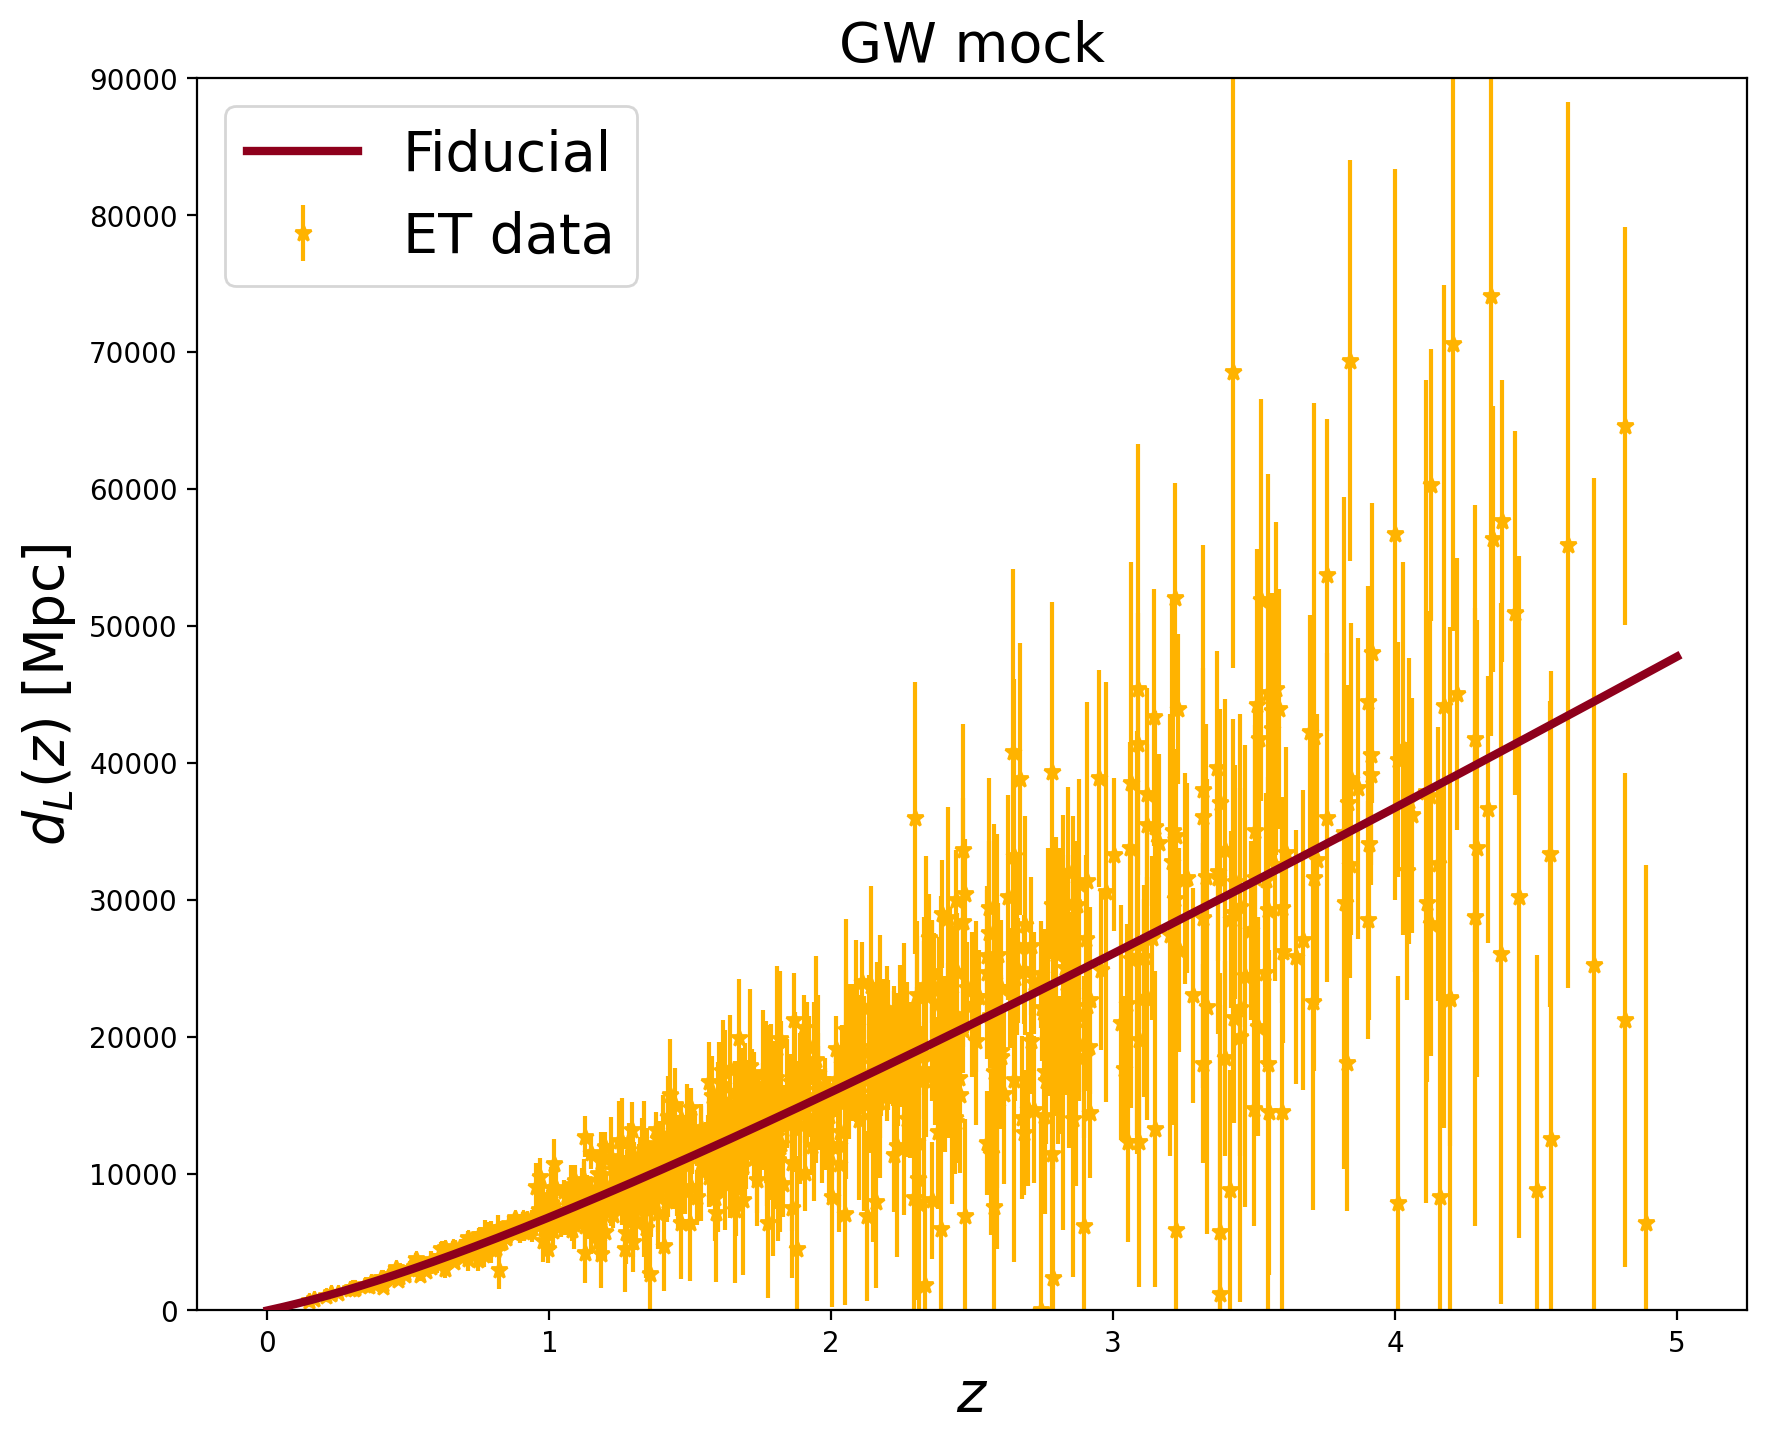

In [9]:
GWdata  = GW.mock()

plt.figure(figsize=(10, 8))
plt.title('GW mock', fontsize = 20)
plt.errorbar(GWdata['z'], GWdata['value'], yerr=GWdata['error'], 
             color='#FFB300', ls='', marker='*', label='ET data', zorder = 0)
plt.plot(zspecs,luminosity_LCDM(zspecs),color='#8E001C',lw=3,label='Fiducial', zorder = 10)
plt.xlabel(r'$z$',fontsize = 20)
plt.ylabel(r'$d_L(z)$ [Mpc]',fontsize = 20)
plt.ylim([0, 90000])
plt.legend(loc='upper left',fontsize = 20)

# plt.savefig('your_path_here/GW_mock.pdf', dpi=300, bbox_inches='tight')

plt.show()

## Plot the redshift distribution

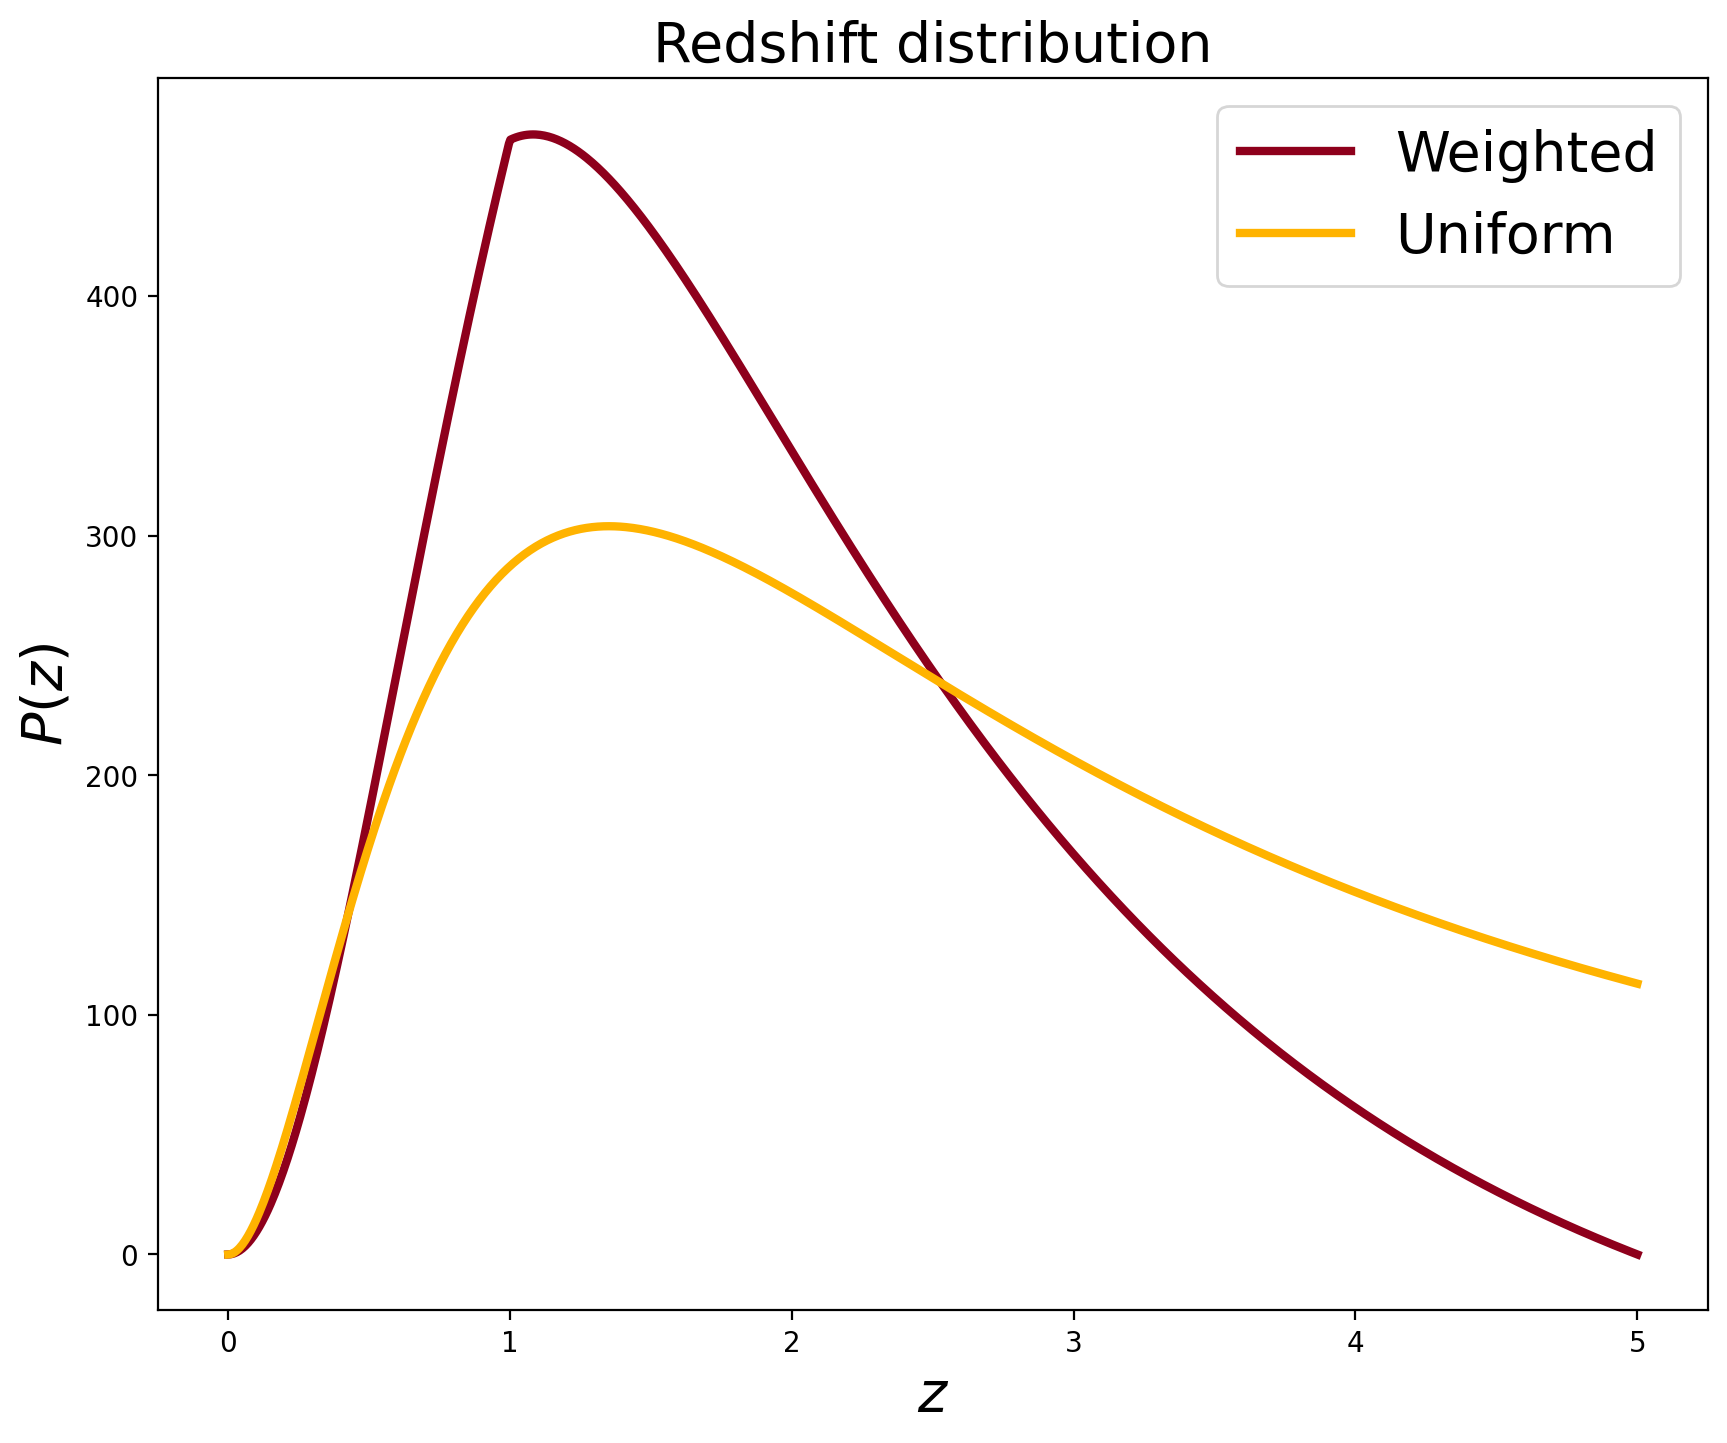

In [10]:
GWparameters['merger_distribution'] = 'weighted'
weight_dist = GW.zdist(specifications,GWparameters)

GWparameters['merger_distribution'] = 'uniform'
uniform_dist = GW.zdist(specifications,GWparameters)

plt.figure(figsize=(10, 8))
plt.title('Redshift distribution', fontsize = 20)
plt.plot(zspecs, weight_dist(zspecs), color = '#8E001C', lw = 3, label = r'Weighted')
plt.plot(zspecs, uniform_dist(zspecs), color = '#FFB300', lw = 3, label = r'Uniform')
plt.xlabel(r'$z$', fontsize = 20)
plt.ylabel(r'$P(z)$', fontsize = 20)
plt.legend(loc='upper right', fontsize = 20)
plt.show()

## Plot the total error and lensing error

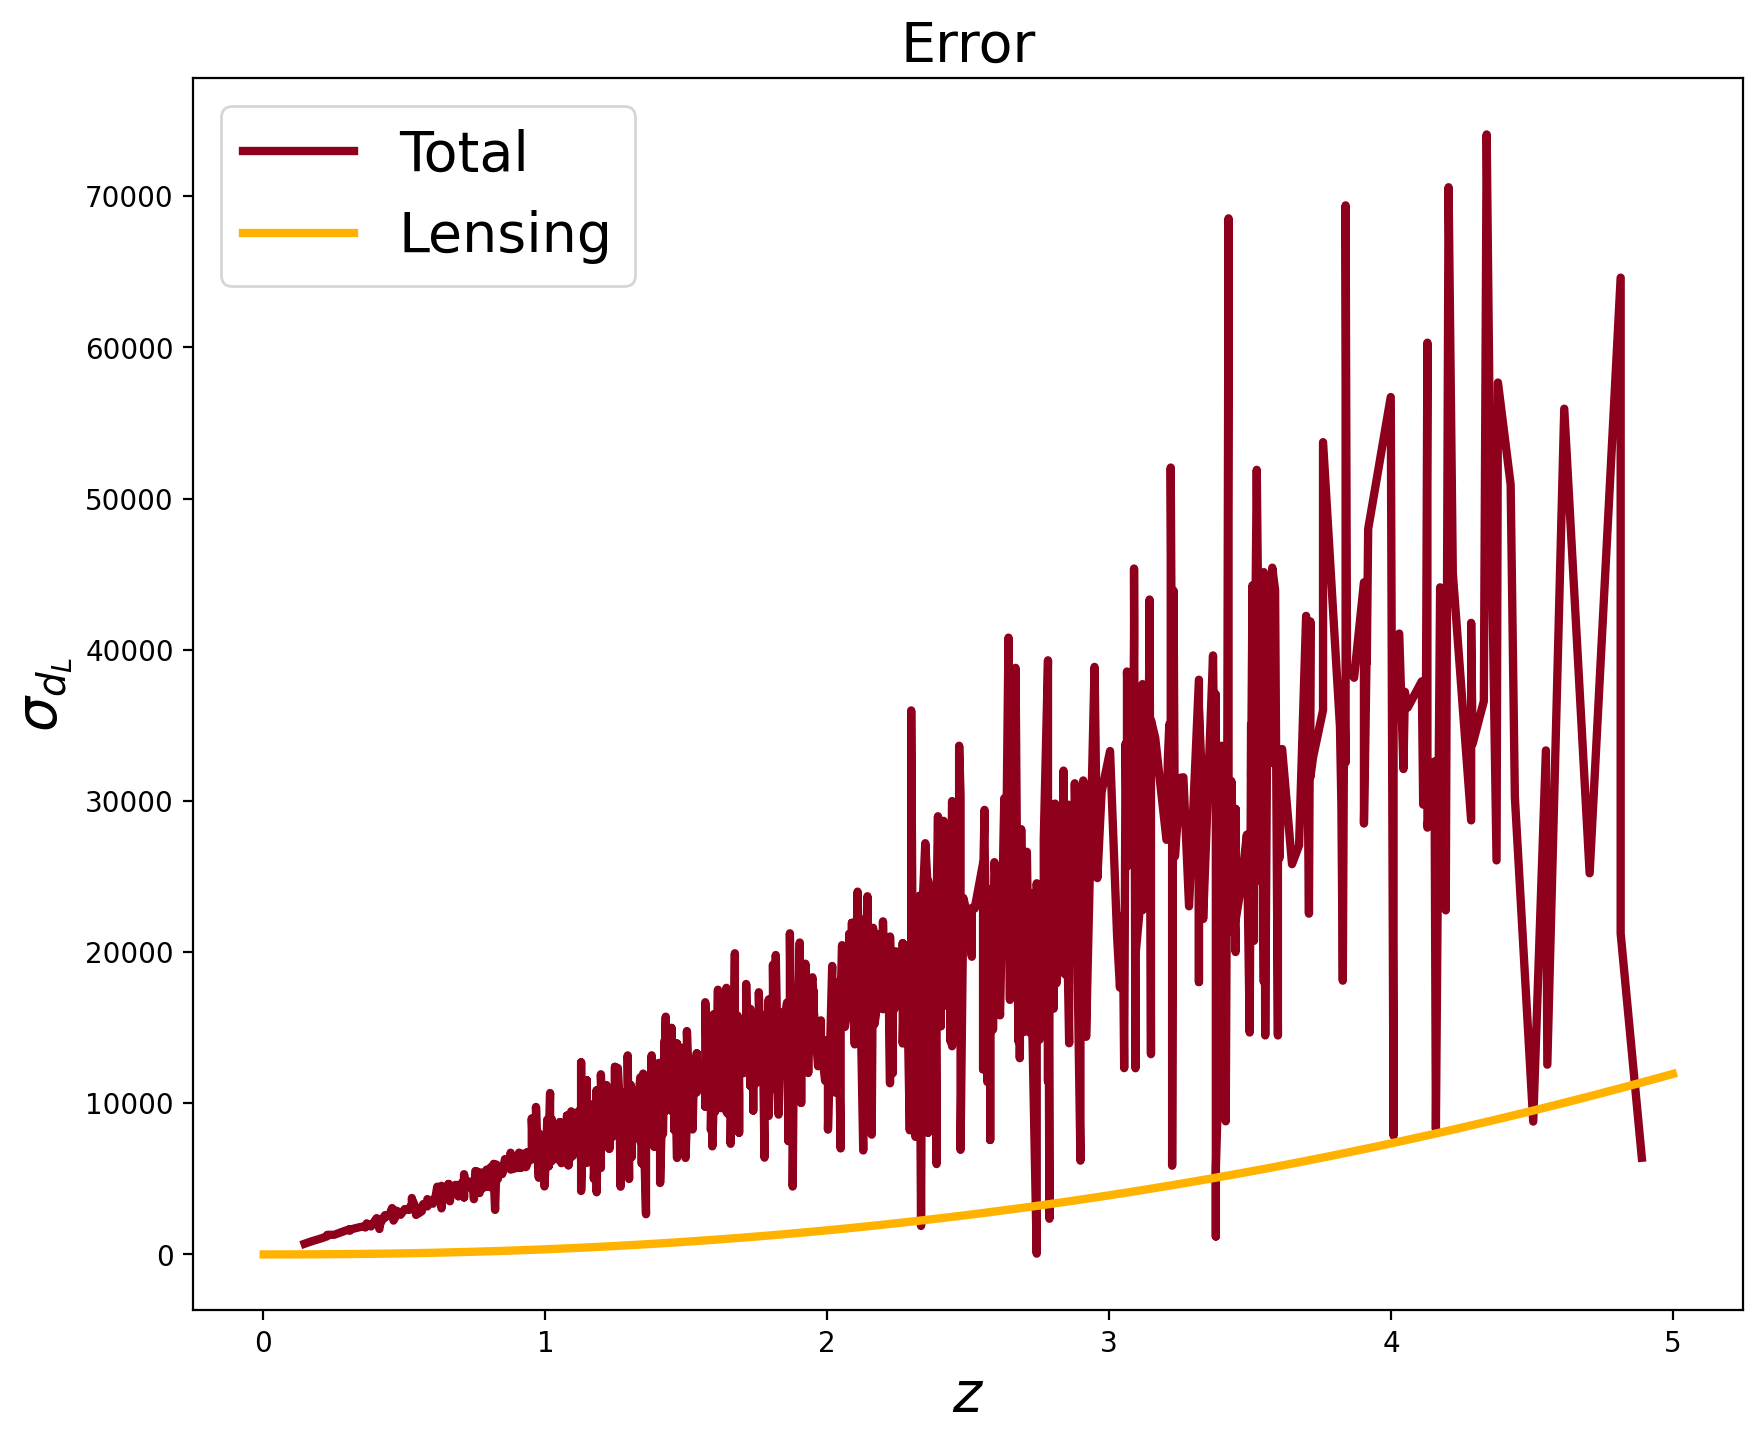

In [11]:
lensnoise = np.array([0.05*zi*luminosity_GW(zi) for zi in zspecs])

plt.figure(figsize=(10, 8))
plt.title('Error', fontsize = 20)
plt.plot(GWdata['z'], GWdata['value'], color = '#8E001C', lw = 3, label = r'Total')
plt.plot(zspecs, lensnoise, color = '#FFB300', lw = 3, label = r'Lensing')
plt.xlabel(r'$z$', fontsize = 20)
plt.ylabel(r'$\sigma_{d_L}$', fontsize = 20)
plt.legend(loc='upper left', fontsize = 20)
plt.show()

## Statistical checks

-----------------------------------REPORT ON GW distance-----------------------------------
Number of outliers: 48
Fraction of data: 4.8%
Maximum fistance from fiducial (in sigma): 3.3837432672065835


/home/nataliehogg/Documents/Projects/davide/horizon/tools/mockchecker.py:62: SyntaxWarning: invalid escape sequence '\s'
  label=r' '+str(self.threshold)+'$\sigma$ outliers ('+str(100*len(self.outliers['x'])/len(self.x))+'% of total)',


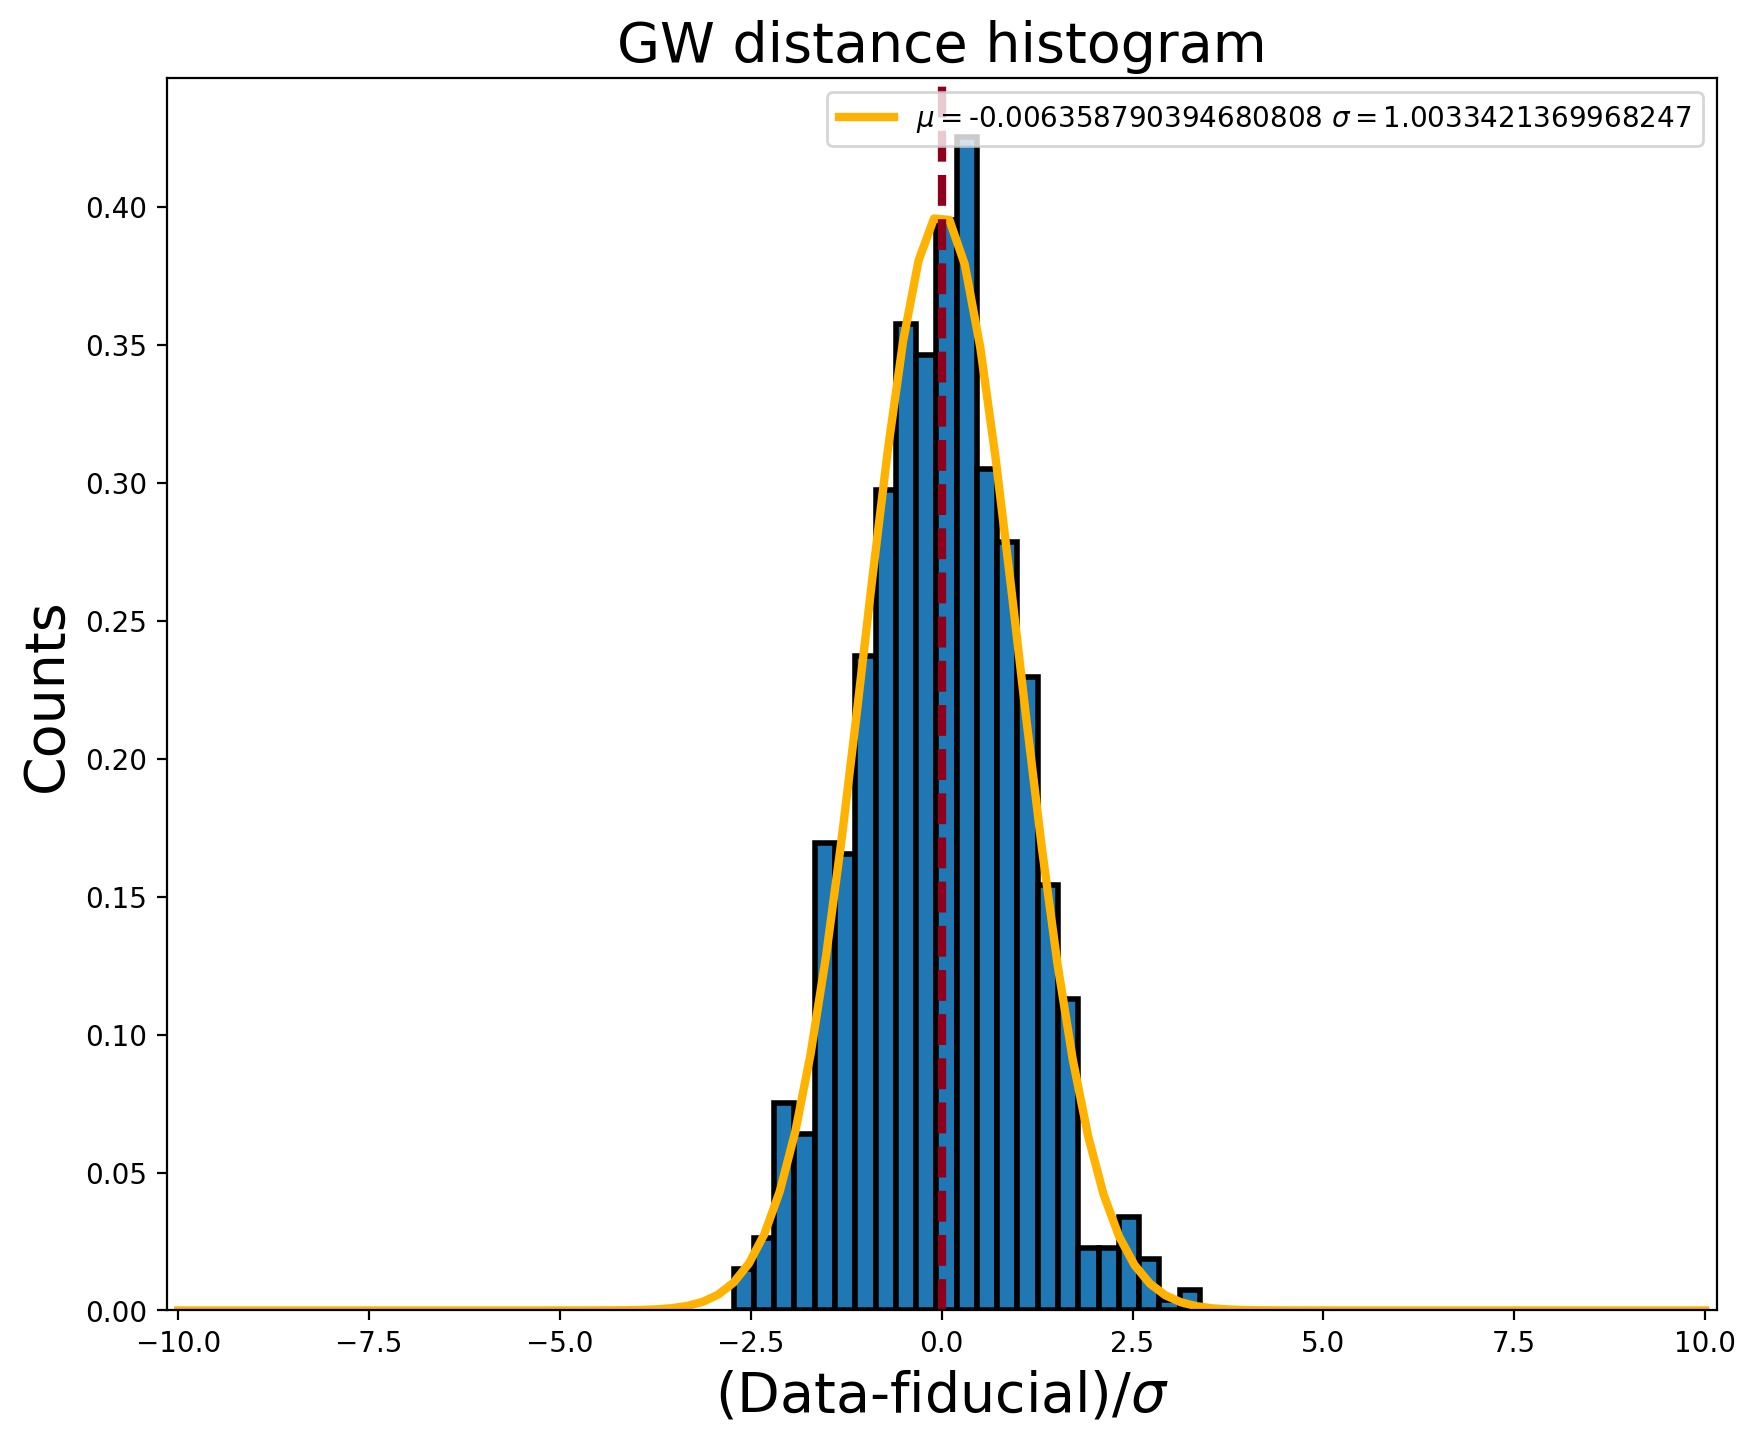

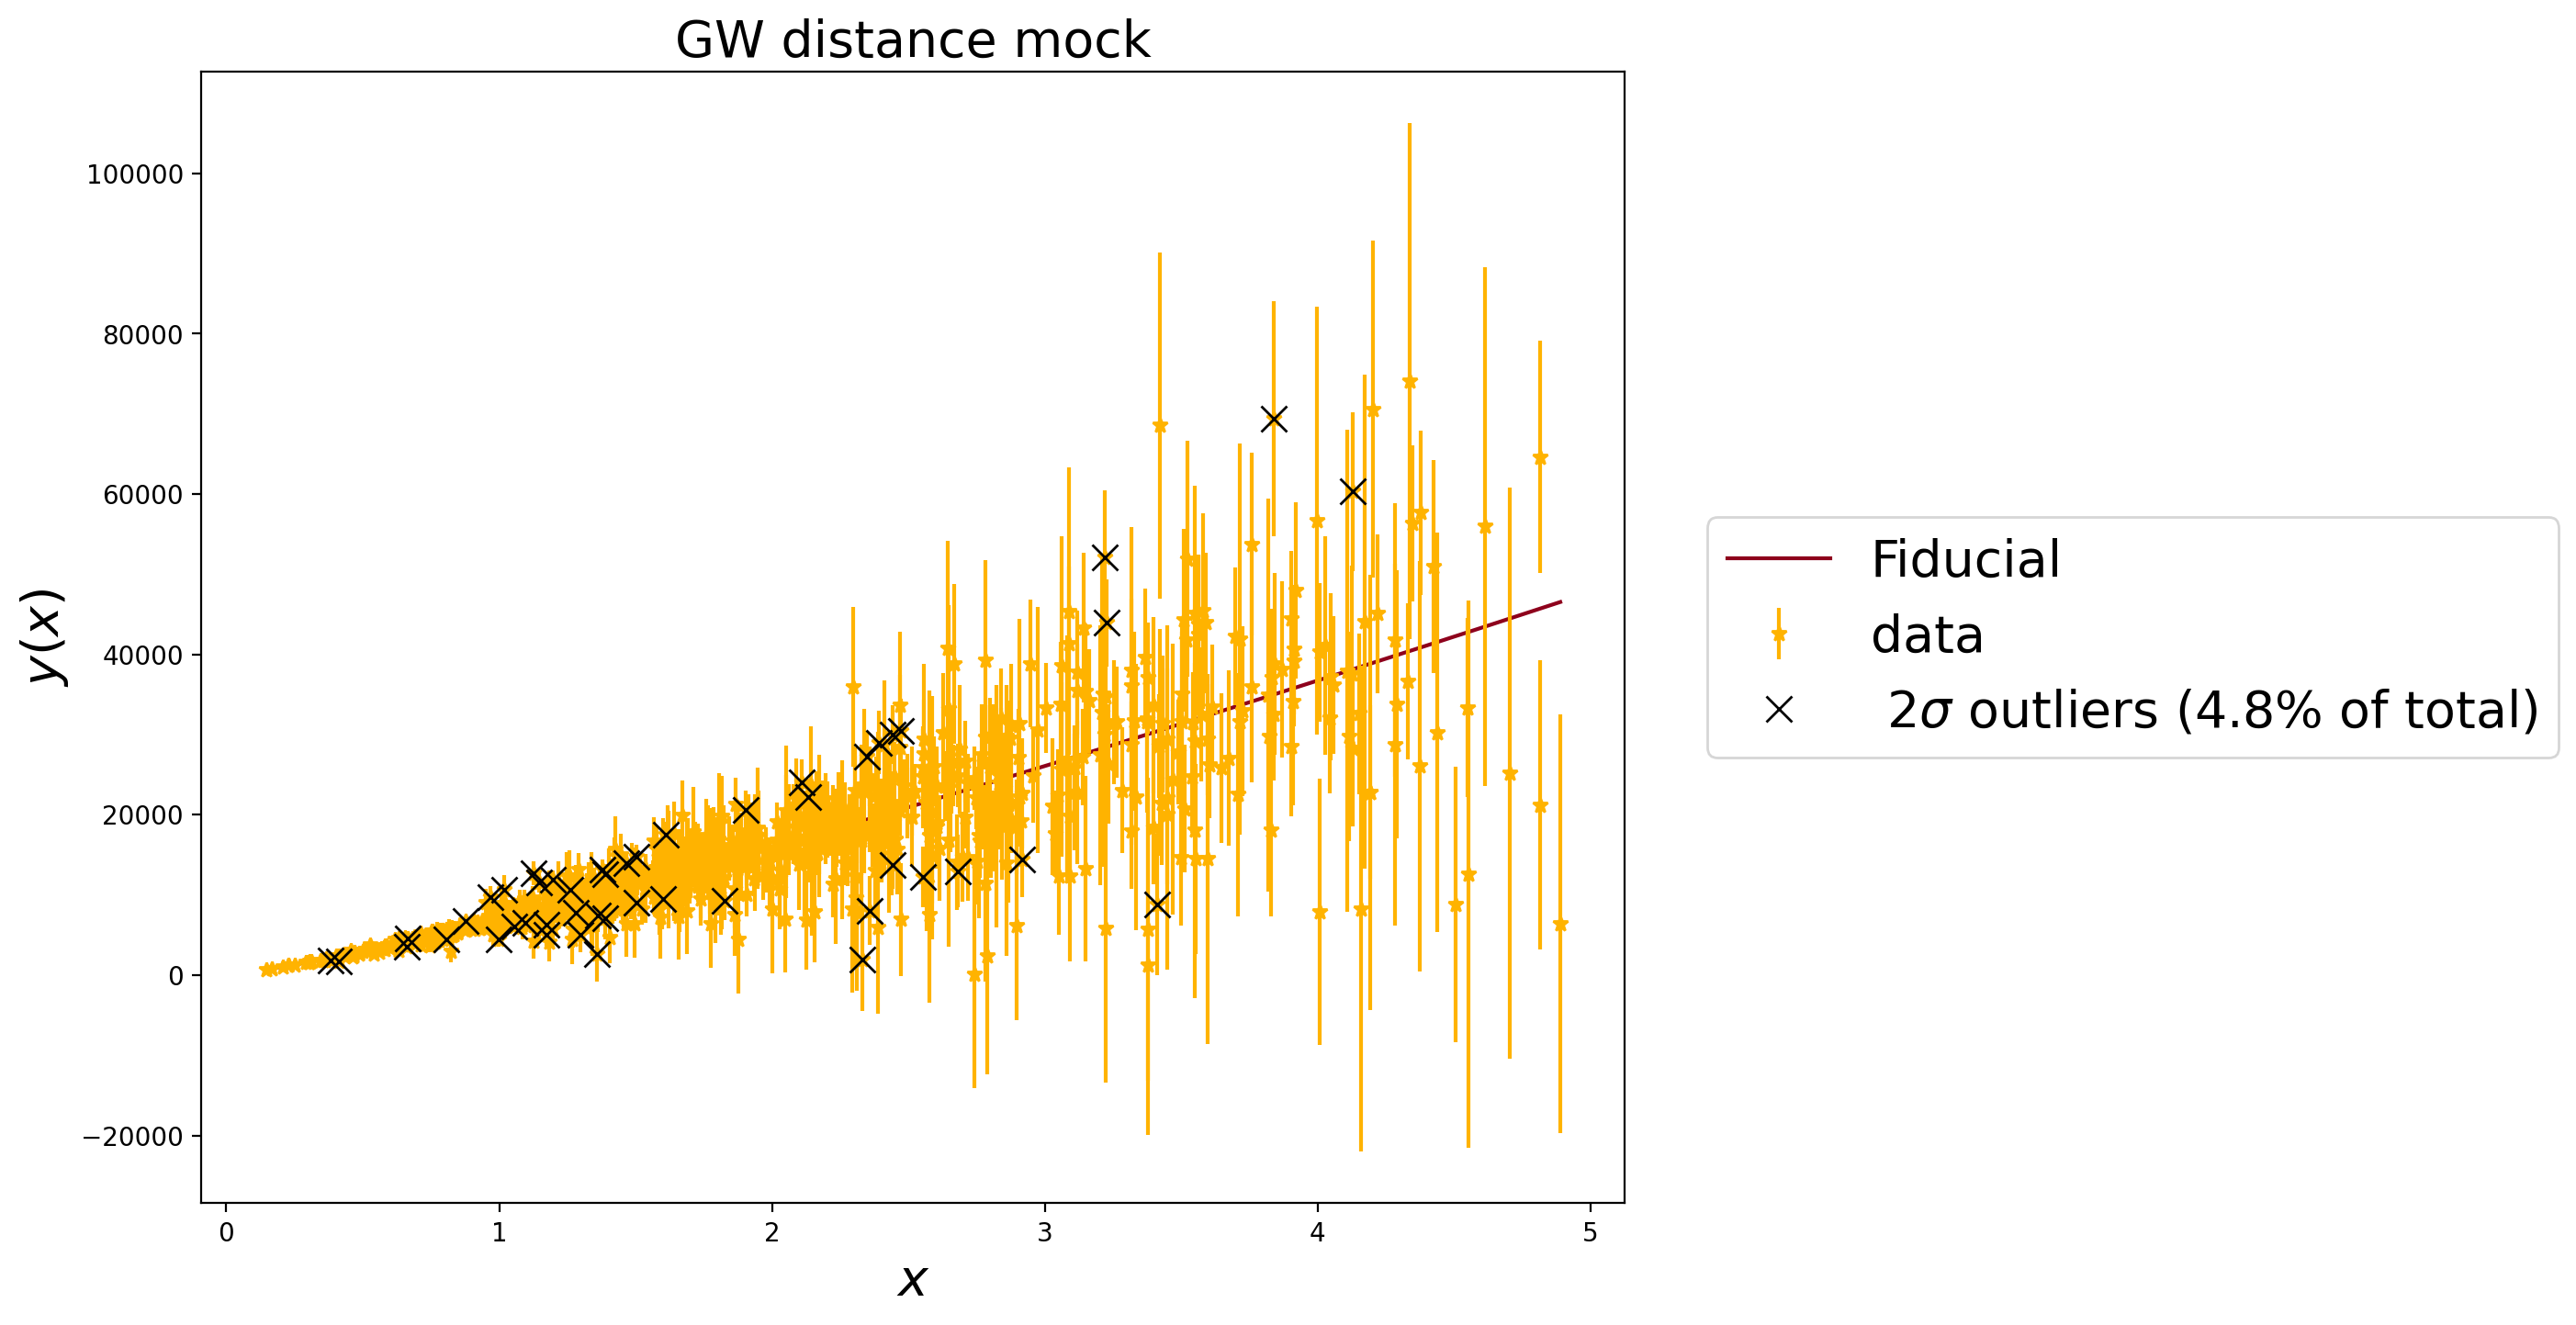

In [12]:
from tools.mockchecker import *

mockchecker(x = GWdata['z'], data = GWdata['value'], error = GWdata['error'],
            fiducial = np.array([luminosity_LCDM(zi) for zi in GWdata['z']]),
            threshold = 2,dataname='GW distance')